<a href="https://colab.research.google.com/github/CHIN-HUA/AI/blob/main/A3_415511001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3: Eyes on the Road
**學號：415511001**

本筆記本包含全部實作，以及本機 NVIDIA RTX 3080 實際執行保留下來的輸出。這些不是 Colab 執行時間或 GPU 的紀錄。程式可在 Colab 從頭執行；建議選擇 GPU 執行階段。跨平台與套件版本可能造成少量數值差異。

固定切分：CIFAR-10 原始索引 0–44999 訓練、45000–49999 驗證。所有種子固定為 0。模型選定後，每個最終模型只評估測試集一次。官方驗證基準：NumPy 21.66%、CNN 72.42%。官方 CNN 測試基準尚未提供。

重新執行第一格會建立新的工作目錄，保留原有檔案。請依順序執行，勿以測試結果調參。

In [1]:
# Create a new runtime working folder; never remove previous files.
from pathlib import Path
import os, uuid
RUN_DIR = Path.cwd() / ('A3_415511001_run_' + uuid.uuid4().hex[:8])
RUN_DIR.mkdir()
os.chdir(RUN_DIR)
print('Working directory:', RUN_DIR)


Working directory: /content/A3_415511001_run_8ad21ef4


In [2]:
%pip -q install threadpoolctl


## Part II：NumPy 模組
前向、反向與 SGD 完全以 NumPy 實作。以下程式會寫出要求繳交的 `nn_numpy.py`。

In [3]:
%%writefile nn_numpy.py
"""NumPy-only layers. Batch losses are means; L2 uses reg/2 * sum(W**2)."""
import numpy as np


def affine_forward(x, w, b):
    return x @ w + b, (x, w, b)


def affine_backward(dout, cache):
    x, w, _ = cache
    return dout @ w.T, x.T @ dout, dout.sum(axis=0)


def relu_forward(x):
    return np.maximum(x, 0), x


def relu_backward(dout, cache):
    return dout * (cache > 0)


def sigmoid_forward(x):
    # Stable for either sign without evaluating exp of a large positive value.
    e = np.exp(-np.abs(x))
    out = np.where(x >= 0, 1 / (1 + e), e / (1 + e))
    return out, out


def sigmoid_backward(dout, cache):
    return dout * cache * (1 - cache)


def softmax_ce_loss(scores, y):
    z = scores - scores.max(axis=1, keepdims=True)
    logp = z - np.log(np.exp(z).sum(axis=1, keepdims=True))
    n = len(y)
    loss = -logp[np.arange(n), y].mean()
    ds = np.exp(logp)
    ds[np.arange(n), y] -= 1
    return loss, ds / n


def hinge_loss(scores, y):
    n = len(y)
    m = np.maximum(0, scores - scores[np.arange(n), y, None] + 1)
    m[np.arange(n), y] = 0
    ds = (m > 0).astype(scores.dtype)
    ds[np.arange(n), y] = -ds.sum(axis=1)
    return m.sum() / n, ds / n


def numerical_gradient(f, x, h=1e-5):
    grad = np.zeros_like(x)
    # A coordinate loop is necessary for finite differences, not a batch loop.
    for index in np.ndindex(x.shape):
        old = x[index].copy()
        try:
            x[index] = old + h
            plus = f(x)
            x[index] = old - h
            minus = f(x)
        finally:
            x[index] = old
        grad[index] = (plus - minus) / (2 * h)
    return grad


class MLP:
    def __init__(self, sizes, activation='relu', init='he', seed=0, dtype=np.float32):
        rng = np.random.default_rng(seed)
        self.activation = activation
        self.params = []
        for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
            std = {'zero': 0., 'small': .01, 'large': 1.,
                   'he': np.sqrt(2 / fan_in)}[init]
            self.params.extend([(rng.normal(size=(fan_in, fan_out)) * std).astype(dtype),
                                np.zeros(fan_out, dtype=dtype)])

    def scores(self, x, cache=False):
        saved = []
        act = relu_forward if self.activation == 'relu' else sigmoid_forward
        for i in range(0, len(self.params), 2):
            x, fc = affine_forward(x, *self.params[i:i+2])
            ac = None
            if i < len(self.params) - 2:
                x, ac = act(x)
            saved.append((fc, ac))
        return (x, saved) if cache else x

    def loss(self, x, y, reg=0., kind='softmax'):
        scores, saved = self.scores(x, cache=True)
        lossfn = softmax_ce_loss if kind == 'softmax' else hinge_loss
        loss, dx = lossfn(scores, y)
        grads = [None] * len(self.params)
        back = relu_backward if self.activation == 'relu' else sigmoid_backward
        for layer in reversed(range(len(saved))):
            fc, ac = saved[layer]
            if ac is not None:
                dx = back(dx, ac)
            dx, dw, db = affine_backward(dx, fc)
            w = self.params[2 * layer]
            loss += reg / 2 * np.sum(w * w)
            grads[2 * layer:2 * layer+2] = [dw + reg * w, db]
        return loss, grads


def gradient_checks():
    rng = np.random.default_rng(0)
    rows = []
    def check(name, analytic, f, x):
        numeric = numerical_gradient(f, x)
        error = np.max(np.abs(analytic - numeric) /
                       np.maximum(1e-8, np.abs(analytic) + np.abs(numeric)))
        rows.append((name, float(error)))
        assert error < 1e-6, (name, error)
    x = rng.normal(size=(4, 4))
    w = rng.normal(size=(4, 5))
    b = rng.normal(size=5)
    dout = rng.normal(size=(4, 5))
    _, cache = affine_forward(x, w, b)
    dx, dw, db = affine_backward(dout, cache)
    f = lambda _: np.sum(affine_forward(x, w, b)[0] * dout)
    for name, a, v in [('x', dx, x), ('w', dw, w), ('b', db, b)]:
        check('affine/' + name, a, f, v)
    for name, forward, backward in [('relu', relu_forward, relu_backward),
                                     ('sigmoid', sigmoid_forward, sigmoid_backward)]:
        v = rng.uniform(.2, 1.5, (4, 4)) * rng.choice([-1, 1], (4, 4))
        d = rng.normal(size=v.shape)
        _, cache = forward(v)
        check(name, backward(d, cache), lambda z: np.sum(forward(z)[0] * d), v)
    y = np.array([0, 0, 1, 2])
    for kind, fn in [('softmax', softmax_ce_loss), ('hinge', hinge_loss)]:
        s = rng.normal(size=(4, 3))
        check(kind + '/scores', fn(s, y)[1], lambda z: fn(z, y)[0], s)
        for act in ['relu', 'sigmoid']:
            net = MLP([4, 5, 3], activation=act, dtype=np.float64)
            # Check weights and biases of BOTH layers, with regularization.
            _, grads = net.loss(x, y, reg=.03, kind=kind)
            for j, (p, g) in enumerate(zip(net.params, grads)):
                check(f'{act}/{kind}/' + ['W1', 'b1', 'W2', 'b2'][j], g,
                      lambda _: net.loss(x, y, reg=.03, kind=kind)[0], p)
    return rows


if __name__ == '__main__':
    for name, error in gradient_checks():
        print(f'{name:25s} {error:.3e}')



Writing nn_numpy.py


## 實驗實作
包含資料載入、50 張影像檢查、四組超參數、hinge 比較、五層網路實驗、CNN 訓練、四組 dropout 與最後一次測試評估。訓練曲線的 loss 不含正則項，accuracy 使用完整資料集且 CNN 採 eval 模式。

In [4]:
%%writefile experiments.py
"""A3 reproducible experiments. Run: python experiments.py numpy|cnn|final.

Part II models, gradients and optimization use NumPy exclusively. Torchvision
is used only for loading CIFAR-10. Test data is accessed only by `final`.
"""
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ.setdefault('OMP_NUM_THREADS', '4')
from pathlib import Path
import sys, json, time, random, copy
ROOT = Path(__file__).resolve().parent
LOCAL = ROOT.parent.parent / 'tmp'
if (LOCAL / 'sdt_packages').exists():
    sys.path.insert(0, str(LOCAL / 'sdt_packages'))
    sys.path.insert(0, str(LOCAL / 'a3_deps'))
import numpy as np
from nn_numpy import MLP, gradient_checks
from threadpoolctl import threadpool_limits
threadpool_limits(4)
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
DATA = LOCAL / 'a3_data' if LOCAL.exists() else ROOT / 'data'

def save(name, data):
    (OUT / (name + '.json')).write_text(json.dumps(data, indent=2), encoding='utf-8')

def dataset():
    from torchvision.datasets import CIFAR10
    d = CIFAR10(str(DATA), train=True, download=True)
    raw, y = d.data, np.asarray(d.targets, dtype=np.int64)
    bundle = ROOT / 'validation_package/validation_images.npz'
    if bundle.exists():
        a = np.load(bundle)
        assert np.array_equal(a['images'], raw[45000:])
        assert np.array_equal(a['id'], np.arange(45000, 50000))
    mean = (raw[:45000].astype(np.float32) / 255).mean(axis=0, dtype=np.float64).astype(np.float32)
    np.save(OUT / 'mean_image.npy', mean)
    return raw, y, mean

def np_metrics(model, x, y, kind='softmax'):
    from nn_numpy import softmax_ce_loss, hinge_loss
    fn = softmax_ce_loss if kind == 'softmax' else hinge_loss
    loss, correct = 0., 0
    for start in range(0, len(y), 1000):
        xb, yb = x[start:start+1000], y[start:start+1000]
        s = model.scores(xb)
        loss += fn(s, yb)[0] * len(yb)
        correct += (s.argmax(1) == yb).sum()
    return float(loss / len(y)), float(correct / len(y))

def train_np(name, x, y, xv, yv, hidden, lr, reg, epochs=20, kind='softmax', init='he', batch=200):
    model = MLP([3072, *hidden, 10], init=init)
    rng = np.random.default_rng(0)
    history, best, best_params = [], -1., None
    for epoch in range(epochs):
        start_time = time.time()
        order = rng.permutation(len(y))
        # Plain mini-batch SGD; a fixed learning rate for fair configurations.
        for start in range(0, len(y), batch):
            ix = order[start:start+batch]
            loss, gradients = model.loss(x[ix], y[ix], reg=reg, kind=kind)
            if not np.isfinite(loss):
                raise FloatingPointError(name)
            for p, g in zip(model.params, gradients):
                p -= lr * g
        tr_loss, tr_acc = np_metrics(model, x, y, kind)
        va_loss, va_acc = np_metrics(model, xv, yv, kind)
        history.append(dict(epoch=epoch+1, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc))
        if va_acc > best:
            best, best_params = va_acc, [p.copy() for p in model.params]
        print(f'{name} {epoch+1}/{epochs} train={tr_acc:.4f} val={va_acc:.4f} {time.time()-start_time:.1f}s', flush=True)
    model.params = best_params
    config = dict(name=name, hidden=hidden, lr=lr, reg=reg, epochs=epochs, kind=kind, init=init, batch=batch)
    result = dict(config=config, history=history, best_val=best,
                  best_epoch=int(np.argmax([h['val_acc'] for h in history]))+1)
    np.savez(OUT / (name + '.npz'), **{f'p{i}': p for i,p in enumerate(model.params)})
    save(name, result)
    return model, result

def run_numpy():
    random.seed(0); np.random.seed(0)
    checks = gradient_checks()
    save('gradient_checks', checks)
    print('Gradient checks:', checks, flush=True)
    raw, labels, mean = dataset()
    x = (raw.astype(np.float32)/255 - mean).reshape(50000, -1)
    xt, xv, yt, yv = x[:45000], x[45000:], labels[:45000], labels[45000:]
    # Tiny-set sanity test: no validation-based choices on these 50 examples.
    small = MLP([3072, 100, 10])
    sanity = []
    for step in range(1000):
        loss, grads = small.loss(xt[:50], yt[:50])
        for p,g in zip(small.params, grads): p -= .05*g
        if step % 20 == 0:
            loss, acc = np_metrics(small, xt[:50], yt[:50])
            sanity.append(dict(step=step, loss=loss, acc=acc))
            if acc == 1. and loss < .02: break
    save('sanity', sanity)
    assert sanity[-1]['acc'] == 1., '50-image overfit failed'
    configurations = [(100,.03,1e-4),(100,.1,1e-4),(256,.03,1e-4),(256,.03,1e-3)]
    rows = []
    for i,(h,lr,reg) in enumerate(configurations):
        _, r = train_np(f'np_config{i+1}', xt,yt,xv,yv,[h],lr,reg)
        rows.append(r)
    best = max(rows,key=lambda r:r['best_val'])
    c = best['config']
    _, hinge = train_np('np_hinge',xt,yt,xv,yv,c['hidden'],c['lr'],c['reg'],kind='hinge')
    # Factorial comparison: four initializations x two activations, same batch.
    grad_rows = []
    for act in ['relu','sigmoid']:
        for init in ['zero','small','large','he']:
            m = MLP([3072,100,100,100,100,100,10], activation=act, init=init, dtype=np.float64)
            loss,g = m.loss(xt[:200].astype(np.float64),yt[:200],reg=0.)
            grad_rows.append(dict(activation=act,init=init,loss=float(loss),
                                  mean_abs=[float(np.abs(a).mean()) for a in g[::2]]))
    save('initialization',grad_rows)
    deep = []
    for i,reg in enumerate([0.,1e-4,1e-2]):
        _,r = train_np(f'np_deep{i}',xt,yt,xv,yv,[100]*5,.03,reg,epochs=15)
        deep.append(r)
    # Final Part II model chosen only from the four softmax trials and hinge trial.
    chosen = max(rows+[hinge],key=lambda r:r['best_val'])
    save('numpy_summary',dict(configurations=rows,hinge=hinge,deep=deep,selected=chosen['config']['name'],
                              official_baseline=.2166))
    print('NUMPY COMPLETE:',chosen['config']['name'],chosen['best_val'],flush=True)

def torch_setup():
    import torch
    random.seed(0); np.random.seed(0); torch.manual_seed(0)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(0)
    torch.set_num_threads(4)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)
    return torch, torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def make_cnn(dropout):
    import torch.nn as nn
    layers = []
    cin = 3
    for cout in [32,64,128]:
        layers += [nn.Conv2d(cin,cout,3,padding=1,bias=False),nn.BatchNorm2d(cout),nn.ReLU(),
                   nn.Conv2d(cout,cout,3,padding=1,bias=False),nn.BatchNorm2d(cout),nn.ReLU(),nn.MaxPool2d(2)]
        cin = cout
    layers += [nn.Flatten(),nn.Dropout(dropout),nn.Linear(128*4*4,128),nn.ReLU(),nn.Dropout(dropout),nn.Linear(128,10)]
    return nn.Sequential(*layers)

def cnn_metrics(model,x,y,batch=256):
    import torch
    import torch.nn.functional as F
    model.eval(); loss=0.; correct=0
    with torch.no_grad():
        for start in range(0,len(y),batch):
            logits=model(x[start:start+batch]); labels=y[start:start+batch]
            loss += float(F.cross_entropy(logits,labels,reduction='sum'))
            correct += int((logits.argmax(1)==labels).sum())
    return loss/len(y), correct/len(y)

def augment(x):
    import torch
    import torch.nn.functional as F
    # Per-image random horizontal flip and 32x32 crop after 4-pixel reflection pad.
    n=len(x)
    x=torch.where((torch.rand(n,1,1,1,device=x.device)<.5),x.flip(-1),x)
    x=F.pad(x,(4,4,4,4),mode='reflect')
    oy=torch.randint(0,9,(n,1,1),device=x.device)
    ox=torch.randint(0,9,(n,1,1),device=x.device)
    yy=oy+torch.arange(32,device=x.device).view(1,32,1)
    xx=ox+torch.arange(32,device=x.device).view(1,1,32)
    return x.permute(0,2,3,1)[torch.arange(n,device=x.device)[:,None,None],yy,xx].permute(0,3,1,2).contiguous()

def run_cnn():
    torch,device=torch_setup()
    import torch.nn.functional as F
    raw,labels,mean=dataset()
    x=torch.from_numpy(raw.transpose(0,3,1,2).copy()).to(device,dtype=torch.float32)/255
    x-=torch.from_numpy(mean.transpose(2,0,1).copy()).to(device)[None]
    y=torch.from_numpy(labels).to(device)
    xt,xv,yt,yv=x[:45000],x[45000:],y[:45000],y[45000:]
    rows=[]
    for dropout in [0.,.15,.3,.5]:
        torch_setup()
        model=make_cnn(dropout).to(device)
        name='cnn_drop'+str(dropout).replace('.','p')
        optimizer=torch.optim.Adam(model.parameters(),lr=.001,weight_decay=1e-4)
        scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=20)
        history=[]; best=-1.; best_state=None
        for epoch in range(20):
            start_time=time.time(); model.train()
            order=torch.randperm(len(yt),device=device)
            for start in range(0,len(yt),128):
                ix=order[start:start+128]
                optimizer.zero_grad(set_to_none=True)
                logits=model(augment(xt[ix]))
                loss=F.cross_entropy(logits,yt[ix]); loss.backward(); optimizer.step()
            tr_loss,tr_acc=cnn_metrics(model,xt,yt)
            va_loss,va_acc=cnn_metrics(model,xv,yv)
            history.append(dict(epoch=epoch+1,train_loss=tr_loss,train_acc=tr_acc,val_loss=va_loss,val_acc=va_acc,
                                lr=optimizer.param_groups[0]['lr']))
            if va_acc>best:
                best=va_acc; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            scheduler.step()
            save(name,dict(dropout=dropout,history=history,best_val=best,
                           best_epoch=int(np.argmax([h['val_acc'] for h in history]))+1))
            torch.save(best_state,OUT/(name+'.pt'))
            print(f'{name} {epoch+1}/20 train={tr_acc:.4f} val={va_acc:.4f} {time.time()-start_time:.1f}s',flush=True)
        r=json.loads((OUT/(name+'.json')).read_text()); r['name']=name; rows.append(r)
    chosen=max(rows,key=lambda r:r['best_val'])
    save('cnn_summary',dict(configurations=rows,selected=chosen['name'],official_baseline=.7242,
                           device=str(device),torch_version=torch.__version__,numpy_version=np.__version__))
    # Layer table records trainable parameters (BN running stats are not parameters).
    model=make_cnn(chosen['dropout']); dummy=torch.zeros(1,3,32,32); layers=[]
    model.eval()
    with torch.no_grad():
        for i,layer in enumerate(model):
            dummy=layer(dummy)
            layers.append(dict(index=i,layer=str(layer),shape=list(dummy.shape[1:]),
                               parameters=sum(p.numel() for p in layer.parameters())))
    save('cnn_layers',layers)
    print('CNN COMPLETE:',chosen['name'],chosen['best_val'],flush=True)

def final_evaluation():
    # Cached return prevents accidental repeated evaluation during notebook reruns.
    if (OUT/'final.json').exists():
        print('Final test already evaluated; showing stored result.')
        print((OUT/'final.json').read_text()); return
    nsum=json.loads((OUT/'numpy_summary.json').read_text())
    csum=json.loads((OUT/'cnn_summary.json').read_text())
    nname,cname=nsum['selected'],csum['selected']
    nr=json.loads((OUT/(nname+'.json')).read_text()); cfg=nr['config']
    cr=json.loads((OUT/(cname+'.json')).read_text())
    selection=dict(numpy=nname,cnn=cname,numpy_val=nr['best_val'],cnn_val=cr['best_val'])
    save('frozen_selection',selection)  # Persist the decision BEFORE loading test data.
    from torchvision.datasets import CIFAR10
    d=CIFAR10(str(DATA),train=False,download=True)
    mean=np.load(OUT/'mean_image.npy')
    x=d.data.astype(np.float32)/255-mean; y=np.asarray(d.targets)
    m=MLP([3072,*cfg['hidden'],10]); z=np.load(OUT/(nname+'.npz'))
    m.params=[z[f'p{i}'] for i in range(len(m.params))]
    nl,na=np_metrics(m,x.reshape(10000,-1),y,cfg['kind'])
    torch,device=torch_setup(); cnn=make_cnn(cr['dropout']).to(device)
    cnn.load_state_dict(torch.load(OUT/(cname+'.pt'),map_location=device,weights_only=True))
    cl,ca=cnn_metrics(cnn,torch.from_numpy(x.transpose(0,3,1,2).copy()).to(device),torch.from_numpy(y).to(device))
    result=dict(**selection,numpy_test=na,cnn_test=ca,numpy_test_loss=nl,cnn_test_loss=cl,
                test_count=10000,official_cnn_test_baseline=None)
    save('final',result); print(json.dumps(result,indent=2),flush=True)
    # Validation predictions are produced separately; no test labels enter exports.
    raw,vy,mean=dataset(); vx=raw[45000:].astype(np.float32)/255-mean
    import csv
    for name,pred in [('partII',m.scores(vx.reshape(5000,-1)).argmax(1))]:
        with (OUT/(name+'_submission.csv')).open('w',newline='') as f:
            w=csv.writer(f); w.writerow(['id','label']); w.writerows(zip(range(45000,50000),pred.tolist()))
    cnn.eval(); predictions=[]
    with torch.no_grad():
        for start in range(0,5000,256):
            b=torch.from_numpy(vx[start:start+256].transpose(0,3,1,2).copy()).to(device)
            predictions.extend(cnn(b).argmax(1).cpu().tolist())
    with (OUT/'partIII_submission.csv').open('w',newline='') as f:
        w=csv.writer(f); w.writerow(['id','label']); w.writerows(zip(range(45000,50000),predictions))

if __name__=='__main__':
    {'numpy':run_numpy,'cnn':run_cnn,'final':final_evaluation}[sys.argv[1]]()


Writing experiments.py


## Part II 執行紀錄
以下保留實際本機執行標準輸出。每一列均為真實 epoch 紀錄；耗時屬於本機環境。

In [5]:
!python -u experiments.py numpy


Gradient checks: [('affine/x', 1.2365272942954316e-10), ('affine/w', 4.593517985224261e-10), ('affine/b', 2.7636640850364918e-11), ('relu', 6.778680636723541e-11), ('sigmoid', 2.0741229268162455e-10), ('softmax/scores', 2.174303892040688e-10), ('relu/softmax/W1', 3.3492399566891395e-10), ('relu/softmax/b1', 2.6855401166360806e-10), ('relu/softmax/W2', 1.5603473737200498e-10), ('relu/softmax/b2', 2.2197811452473545e-11), ('sigmoid/softmax/W1', 5.384546988762754e-09), ('sigmoid/softmax/b1', 5.85443031047992e-10), ('sigmoid/softmax/W2', 5.292837994351461e-10), ('sigmoid/softmax/b2', 6.419180722374284e-10), ('hinge/scores', 2.548006250370796e-11), ('relu/hinge/W1', 1.6813909938495488e-09), ('relu/hinge/b1', 9.953643460206962e-11), ('relu/hinge/W2', 1.5457060099592375e-10), ('relu/hinge/b2', 2.548006250370796e-11), ('sigmoid/hinge/W1', 2.8486334774481314e-09), ('sigmoid/hinge/b1', 1.0251592555452842e-09), ('sigmoid/hinge/W2', 1.0424534557511706e-09), ('sigmoid/hinge/b2', 2.548006250370796e-

## Part III 執行紀錄
CNN 從零訓練，未使用外部資料或預訓練權重。只以驗證準確率選擇 dropout 與 checkpoint。

In [6]:
!python -u experiments.py cnn


cnn_drop0p0 1/20 train=0.5854 val=0.5848 9.2s
cnn_drop0p0 2/20 train=0.6585 val=0.6598 6.8s
cnn_drop0p0 3/20 train=0.7397 val=0.7358 6.9s
cnn_drop0p0 4/20 train=0.7601 val=0.7590 6.9s
cnn_drop0p0 5/20 train=0.7988 val=0.7786 6.9s
cnn_drop0p0 6/20 train=0.7880 val=0.7790 7.0s
cnn_drop0p0 7/20 train=0.8524 val=0.8304 7.0s
cnn_drop0p0 8/20 train=0.8477 val=0.8310 7.0s
cnn_drop0p0 9/20 train=0.8785 val=0.8484 7.1s
cnn_drop0p0 10/20 train=0.8900 val=0.8542 7.1s
cnn_drop0p0 11/20 train=0.8927 val=0.8574 7.2s
cnn_drop0p0 12/20 train=0.9027 val=0.8570 7.2s
cnn_drop0p0 13/20 train=0.9093 val=0.8704 7.3s
cnn_drop0p0 14/20 train=0.9171 val=0.8732 7.3s
cnn_drop0p0 15/20 train=0.9182 val=0.8752 7.3s
cnn_drop0p0 16/20 train=0.9317 val=0.8844 7.4s
cnn_drop0p0 17/20 train=0.9351 val=0.8870 7.5s
cnn_drop0p0 18/20 train=0.9359 val=0.8856 7.5s
cnn_drop0p0 19/20 train=0.9400 val=0.8890 7.6s
cnn_drop0p0 20/20 train=0.9399 val=0.8894 7.7s
cnn_drop0p15 1/20 train=0.5927 val=0.5980 7.7s
cnn_drop0p15 2/20 trai

## 最終評估
程式先保存模型選擇，再讀取測試集。已有 `final.json` 時，只讀取原紀錄，避免重複評估。

In [7]:
!python -u experiments.py final


{
  "numpy": "np_config2",
  "cnn": "cnn_drop0p0",
  "numpy_val": 0.5352,
  "cnn_val": 0.8894,
  "numpy_test": 0.5192,
  "cnn_test": 0.8823,
  "numpy_test_loss": 1.3723018169403076,
  "cnn_test_loss": 0.3489711256980896,
  "test_count": 10000,
  "official_cnn_test_baseline": null
}


## 表格與曲線產生器
所有圖表由 JSON 實測紀錄產生。報告使用相同數據。

In [8]:
%%writefile build_report.py
"""Generate report tables/figures directly from the recorded experiment outputs."""
from experiments import ROOT, OUT, save, gradient_checks
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
                     'figure.dpi':140,'savefig.bbox':'tight','pdf.fonttype':42})

def read(name): return json.loads((OUT/(name+'.json')).read_text(encoding='utf-8'))
def write(name,s): (OUT/(name+'.tex')).write_text(s,encoding='utf-8')
def pct(x): return f'{100*x:.2f}\\%'
def sci(x):
    mantissa, exponent = f'{x:.3e}'.split('e')
    return rf'${mantissa}\times10^{{{int(exponent)}}}$'
def esc(s): return str(s).replace('_',r'\_')
def table(name,headers,rows,cols=None):
    cols=cols or ('l'+'r'*(len(headers)-1))
    text=r'\begin{table}[htbp]\centering\small\begin{tabular}{'+cols+r'}\toprule'+'\n'
    text+=' & '.join(headers)+r'\\\midrule'+'\n'
    text+='\n'.join(' & '.join(map(str,row))+r'\\' for row in rows)
    text+='\n'+r'\bottomrule\end{tabular}\end{table}'
    write(name,text)
def finish(name):
    plt.tight_layout(); plt.savefig(OUT/(name+'.pdf')); plt.savefig(OUT/(name+'.png')); plt.close()
def curves(name,r,baseline):
    h=r['history']; e=[a['epoch'] for a in h]
    fig,ax=plt.subplots(1,2,figsize=(8,3.0))
    for split,label in [('train','Train'),('val','Validation')]:
        ax[0].plot(e,[a[split+'_loss'] for a in h],label=label)
        ax[1].plot(e,[100*a[split+'_acc'] for a in h],label=label)
    ax[0].set(ylabel='Data loss',xlabel='Epoch'); ax[1].set(ylabel='Accuracy (%)',xlabel='Epoch')
    ax[1].axhline(100*baseline,color='gray',ls='--',label='TA validation baseline')
    for a in ax: a.grid(alpha=.2); a.legend(fontsize=9)
    finish(name)

def build():
    checks=gradient_checks(); save('gradient_checks',checks)
    table('gradient_table',['檢查項目','最大相對誤差'],[(esc(n),sci(e)) for n,e in checks])
    if not (OUT/'numpy_summary.json').exists(): return
    n=read('numpy_summary'); nr=read(n['selected']); sanity=read('sanity')
    write('sanity_text',f"在記錄的第 {sanity[-1]['step']+1} 次更新後，50 張影像訓練準確率為 {pct(sanity[-1]['acc'])}，交叉熵為 {sanity[-1]['loss']:.4f}，通過基本檢查。")
    fig,ax=plt.subplots(1,2,figsize=(8,2.8))
    ax[0].plot([r['step']+1 for r in sanity],[r['loss'] for r in sanity]); ax[0].set(xlabel='SGD updates',ylabel='Cross-entropy')
    ax[1].plot([r['step']+1 for r in sanity],[100*r['acc'] for r in sanity]); ax[1].set(xlabel='SGD updates',ylabel='Training accuracy (%)')
    finish('sanity')
    table('numpy_table',['設定','隱藏單元','學習率','L2','最佳 epoch','驗證準確率'],
          [(str(i+1),r['config']['hidden'][0],r['config']['lr'],r['config']['reg'],r['best_epoch'],pct(r['best_val'])) for i,r in enumerate(n['configurations'])])
    curves('numpy_curves',nr,.2166)
    soft=max(n['configurations'],key=lambda r:r['best_val']); hinge=n['hinge']
    selected_loss=nr['config']['kind']
    write('loss_comparison',f"最佳 softmax 設定的驗證準確率為 {pct(soft['best_val'])}；相同超參數下 hinge 為 {pct(hinge['best_val'])}。"
          f"最終 Part II 選用 {selected_loss}，驗證準確率 {pct(nr['best_val'])}，比官方 21.66\\% 高 {(nr['best_val']-.2166)*100:.2f} 個百分點。"
          f"此比較僅控制同一組超參數，未為 hinge 另做完整學習率搜尋，因此不代表兩種損失在各自最佳設定下的普遍優劣。")
    init=read('initialization'); fig,ax=plt.subplots(1,2,figsize=(8,3.2),sharey=True)
    for a,act in zip(ax,['relu','sigmoid']):
        for r in init:
            if r['activation']==act: a.plot(range(1,7),r['mean_abs'],marker='o',label=r['init'])
        a.set(yscale='symlog',xlabel='Layer',title=act.upper(),xticks=range(1,7))
        a.set_yscale('symlog',linthresh=1e-12); a.grid(alpha=.2); a.legend(fontsize=9)
    ax[0].set_ylabel('Mean absolute weight gradient'); finish('initialization')
    pieces=[]
    for act in ['relu','sigmoid']:
        for kind in ['zero','small','large','he']:
            r=next(r for r in init if r['activation']==act and r['init']==kind)
            pieces.append(f"{act}/{kind} 的 L1 與 L6 梯度分別為 {sci(r['mean_abs'][0])}、{sci(r['mean_abs'][-1])}。")
    write('initialization_text',' '.join(pieces)+
          ' 全零 ReLU 的權重梯度為零；全零 sigmoid 的輸出權重仍可有梯度，但隱藏權重受到零輸出權重阻斷。'
          '小尺度初始化在深層網路中造成早期層梯度衰減。大尺度 ReLU 的梯度達到數十至數千，顯示訊號尺度過大。'
          '大尺度 sigmoid 雖可能飽和，但大權重亦會放大反傳，因此不能斷言其所有梯度都接近零；本實驗確實仍測得非零梯度。'
          '相同 He 初始化下，ReLU 的早期層梯度明顯大於 sigmoid，且各隱藏層的梯度尺度較一致。')
    rows=[]; fig,ax=plt.subplots(1,2,figsize=(8,3.0))
    for r in n['deep']:
        h=r['history']; b=h[r['best_epoch']-1]; reg=r['config']['reg']
        rows.append((reg,r['best_epoch'],pct(b['train_acc']),pct(b['val_acc']),f"{100*(b['train_acc']-b['val_acc']):.2f}"))
        for a,key in zip(ax,['train_acc','val_acc']):
            a.plot([v['epoch'] for v in h],[100*v[key] for v in h],label=f'L2={reg:g}')
            a.set(xlabel='Epoch',ylabel='Accuracy (%)'); a.grid(alpha=.2); a.legend(fontsize=9)
    ax[0].set_title('Training'); ax[1].set_title('Validation'); finish('regularization')
    table('regularization_table',['L2','最佳 epoch','訓練準確率','驗證準確率','落差（百分點）'],rows)
    bestdeep=max(n['deep'],key=lambda r:r['best_val']); strong=n['deep'][-1]
    write('regularization_text',f"三組中，L2={bestdeep['config']['reg']:g} 的最佳驗證準確率最高，為 {pct(bestdeep['best_val'])}。"
          f"較強的 L2=0.01 得到 {pct(strong['best_val'])}。"
          'L2=0.01 將訓練準確率壓低並縮小泛化落差，但也犧牲部分驗證表現，顯示強正則化的擬合限制。'
          '無正則化與弱正則化的驗證差異很小，不足以推論一般性的優劣。較大的訓練與驗證落差表示過度擬合風險；若兩者皆低則可能欠擬合或尚未收斂。'
          'L2 以收縮權重限制模型複雜度，但強度過大也會犧牲擬合能力。此處只比較相同訓練預算下的結果，不能把尚未收斂與模型容量不足完全等同。')
    if not (OUT/'cnn_summary.json').exists(): return
    c=read('cnn_summary'); cr=read(c['selected']); layers=read('cnn_layers')
    layerrows=[]
    for r in layers:
        desc=r['layer'].split('(')[0]
        if desc=='Conv2d': desc=r'$3\times3$ Conv'
        elif desc=='MaxPool2d': desc=r'$2\times2$ MaxPool'
        elif desc=='Dropout': desc=f"Dropout ({cr['dropout']})"
        shape='$'+r'\times'.join(map(str,r['shape']))+'$'
        layerrows.append((r['index']+1,desc,shape,f"{r['parameters']:,}"))
    layerrows.append(('',r'\textbf{總計}','',f"{sum(r['parameters'] for r in layers):,}"))
    table('cnn_layers_table',['層','操作','輸出形狀（不含 batch）','可訓練參數'],layerrows,cols='llrr')
    write('cnn_result',f"最佳 dropout 為 {cr['dropout']}，第 {cr['best_epoch']} 個 epoch 的驗證準確率為 {pct(cr['best_val'])}，"
          f"比官方 CNN 基準高 {100*(cr['best_val']-.7242):.2f} 個百分點。總可訓練參數為 {sum(r['parameters'] for r in layers):,}，不含 BatchNorm 的 running statistics。")
    curves('cnn_curves',cr,.7242)
    rows=[]; train=[]; vals=[]; ps=[]
    for r in c['configurations']:
        b=r['history'][r['best_epoch']-1]
        rows.append((r['dropout'],r['best_epoch'],pct(b['train_acc']),pct(b['val_acc']),f"{100*(b['train_acc']-b['val_acc']):.2f}"))
        train.append(100*b['train_acc']); vals.append(100*b['val_acc']); ps.append(r['dropout'])
    table('cnn_sensitivity_table',['Dropout','最佳 epoch','訓練準確率','驗證準確率','落差（百分點）'],rows)
    plt.figure(figsize=(7,3.3)); plt.plot(ps,train,'o-',label='Train at selected epoch'); plt.plot(ps,vals,'s-',label='Best validation')
    plt.axhline(72.42,ls='--',color='gray',label='TA validation baseline'); plt.xticks(ps)
    plt.xlabel('Dropout probability'); plt.ylabel('Accuracy (%)'); plt.grid(alpha=.2); plt.legend(fontsize=9); finish('cnn_sensitivity')
    zero=c['configurations'][0]; high=c['configurations'][-1]
    write('cnn_sensitivity_text',f"驗證選擇的最佳值為 $p={cr['dropout']}$。不使用 dropout 時驗證準確率為 {pct(zero['best_val'])}，"
          f"$p=0.5$ 時為 {pct(high['best_val'])}。"
          '本次不使用 dropout 的驗證表現最佳；資料增強、weight decay 與 BatchNorm 已提供一定的正則化效果，額外 dropout 未帶來驗證收益。'
          '搭配訓練準確率可判斷正則化的效果：訓練很高但驗證落後，支持過度擬合的解釋；'
          '若較大的 dropout 使訓練與驗證都降低，則表示在固定預算下過度限制擬合或延緩收斂。'
          '不能只根據 dropout 數值大小預先斷言表現，應以表格與曲線的實測落差判讀。')
    if not (OUT/'final.json').exists(): return
    f=read('final')
    table('final_table',['模型','驗證準確率','測試準確率','測試減驗證（百分點）'],[
        ('NumPy',pct(f['numpy_val']),pct(f['numpy_test']),f"{100*(f['numpy_test']-f['numpy_val']):+.2f}"),
        ('CNN',pct(f['cnn_val']),pct(f['cnn_test']),f"{100*(f['cnn_test']-f['cnn_val']):+.2f}")])
    gap=100*(f['cnn_test']-f['cnn_val']); se=100*np.sqrt(f['cnn_val']*(1-f['cnn_val'])/5000+f['cnn_test']*(1-f['cnn_test'])/10000)
    write('final_analysis',f"CNN 的測試準確率比 NumPy 高 {100*(f['cnn_test']-f['numpy_test']):.2f} 個百分點，"
          '符合卷積的局部連接、權重共享及較深層表徵適合影像分類的預期。兩者亦有最佳化方法、增強與訓練預算的差異，因此不是只改變卷積操作的受控比較。'
          f"CNN 測試與驗證差為 {gap:+.2f} 個百分點。若暫忽略選模偏差，獨立二項抽樣下此差值的近似標準誤為 {se:.2f} 個百分點。"
          '此數值僅作抽樣變異的尺度參考，並非經多重選模校正的信賴區間。驗證集可估計效能量級，但反覆挑選最佳設定與 epoch 會帶來樂觀偏差。')
    write('overview',f"本作業完成手算推導、NumPy 模組與 CNN 實驗。NumPy 最佳驗證準確率為 {pct(f['numpy_val'])}，"
          f"CNN 為 {pct(f['cnn_val'])}；最終測試準確率分別為 {pct(f['numpy_test'])} 與 {pct(f['cnn_test'])}。"
          '所有實驗數值與圖表由實際執行紀錄產生，完整程式與輸出隨作業附上。'
          f"實驗於本機 NVIDIA RTX 3080 執行，NumPy {c['numpy_version']}、PyTorch {esc(c['torch_version'])}；筆記本保留本機輸出並可在 Colab 重現。")
    print('Report tables and figures generated.')

if __name__=='__main__': build()



Writing build_report.py


In [9]:
!python build_report.py


Report tables and figures generated.


### 50 張影像 sanity check

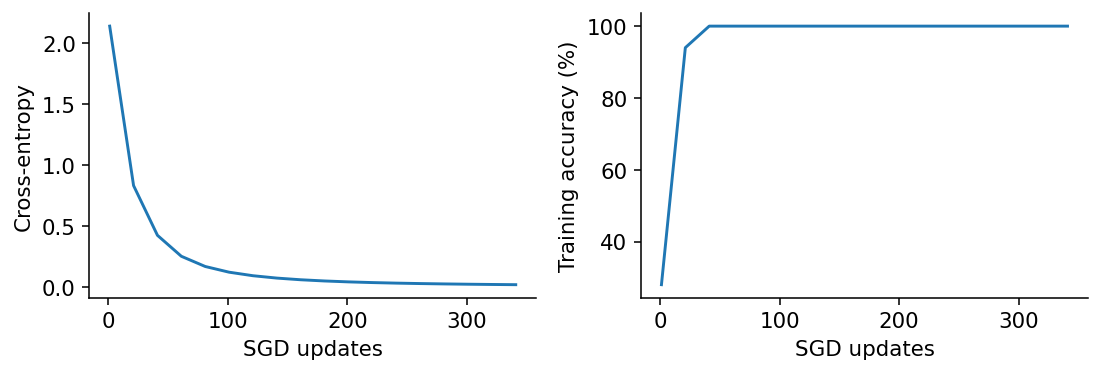

In [10]:
from IPython.display import display, Image
display(Image('results/sanity.png'))

### 最佳 NumPy 模型

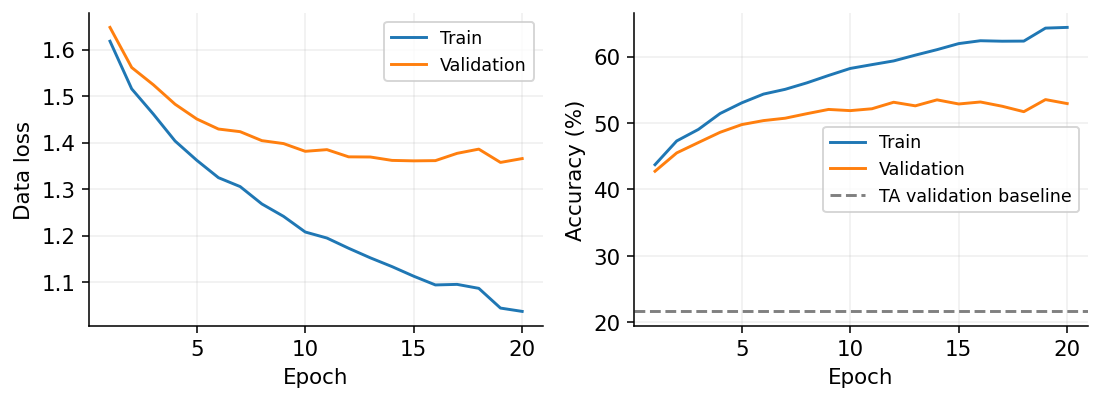

In [11]:
from IPython.display import display, Image
display(Image('results/numpy_curves.png'))

### 初始化與活化函數比較

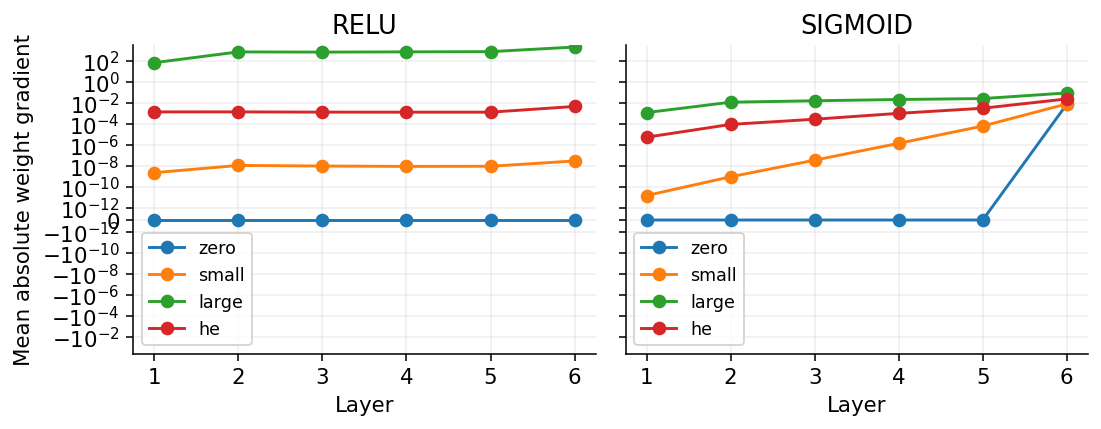

In [12]:
from IPython.display import display, Image
display(Image('results/initialization.png'))

### 五層網路 L2 比較

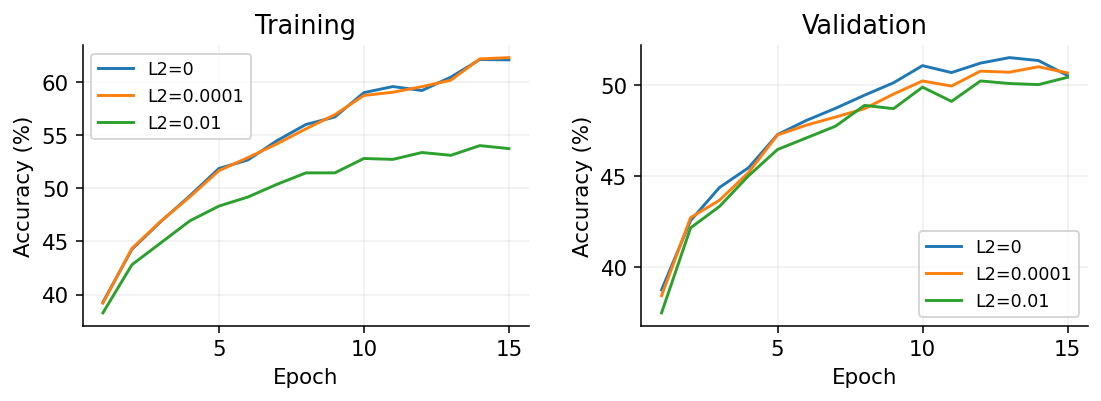

In [13]:
from IPython.display import display, Image
display(Image('results/regularization.png'))

### 最佳 CNN

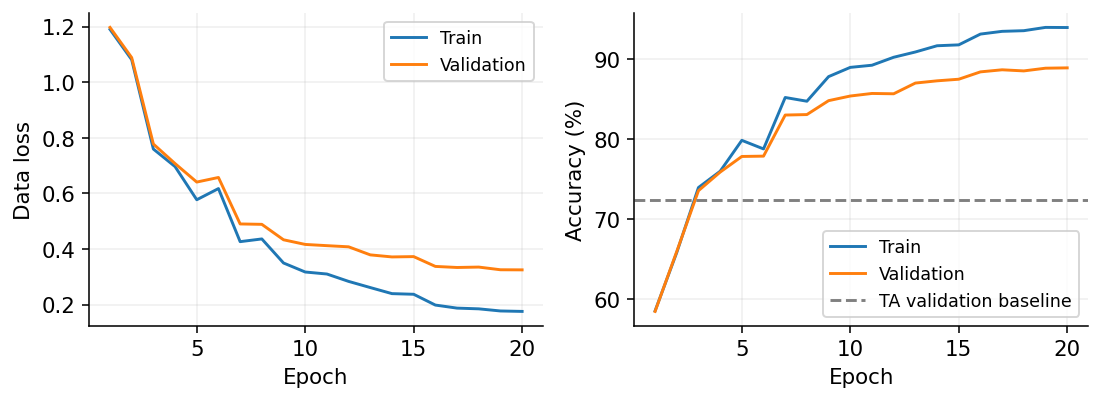

In [14]:
from IPython.display import display, Image
display(Image('results/cnn_curves.png'))

### Dropout 敏感度

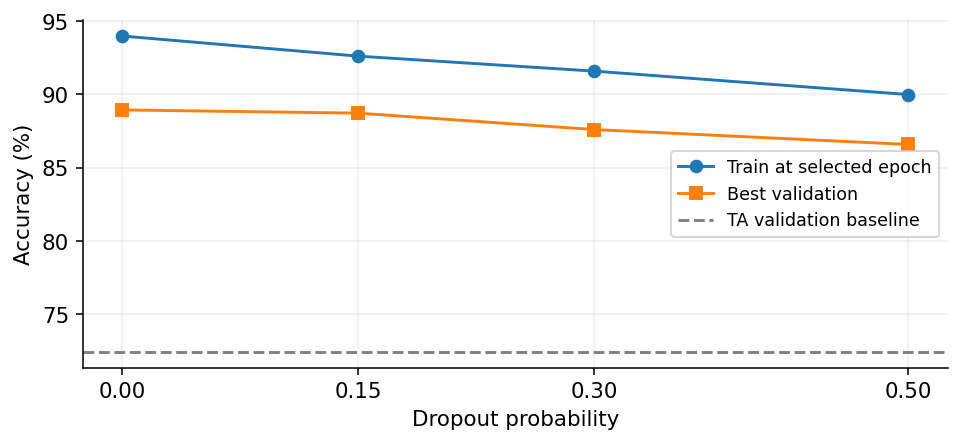

In [15]:
from IPython.display import display, Image
display(Image('results/cnn_sensitivity.png'))

## 數值摘要與模型選擇

In [16]:
import json
from pathlib import Path
print(json.dumps(json.loads(Path('results/final.json').read_text()), indent=2))


{
  "numpy": "np_config2",
  "cnn": "cnn_drop0p0",
  "numpy_val": 0.5352,
  "cnn_val": 0.8894,
  "numpy_test": 0.5192,
  "cnn_test": 0.8823,
  "numpy_test_loss": 1.3723018169403076,
  "cnn_test_loss": 0.3489711256980896,
  "test_count": 10000,
  "official_cnn_test_baseline": null
}


## 匯出執行結果與驗證預測
`partII_submission.csv` 與 `partIII_submission.csv` 是模型對最後 5000 張訓練影像的預測，不是正式測試集結果。此筆記本不自動上傳排行榜或 e3。

Colab：執行後使用「檔案 → 下載 → 下載 .ipynb」保存含輸出的筆記本，再與下列 ZIP 的程式一起繳交。

In [17]:
import zipfile
from pathlib import Path
with zipfile.ZipFile('A3_415511001_runtime_results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for name in ['nn_numpy.py', 'experiments.py', 'build_report.py']:
        z.write(name)
    for p in Path('results').glob('*'):
        if p.is_file(): z.write(p)
from IPython.display import FileLink, display
display(FileLink('A3_415511001_runtime_results.zip'))


/content/A3_415511001_run_8ad21ef4/A3_415511001_runtime_results.zip